In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../data/processed/telco_customer_churn_clean.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [3]:
df.describe(include="object")

C:\Users\USER\AppData\Local\Temp\ipykernel_7248\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,5174


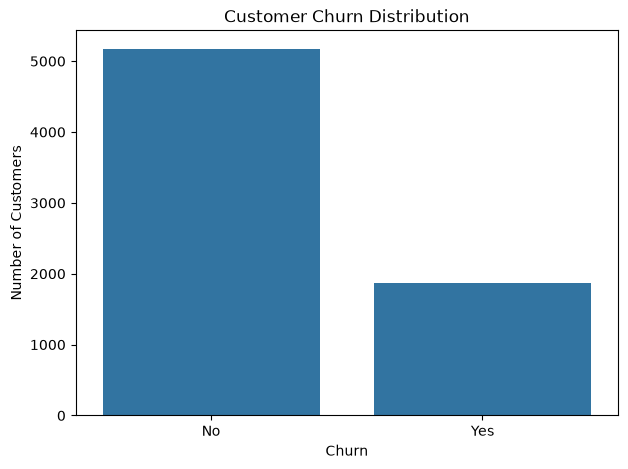

In [4]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

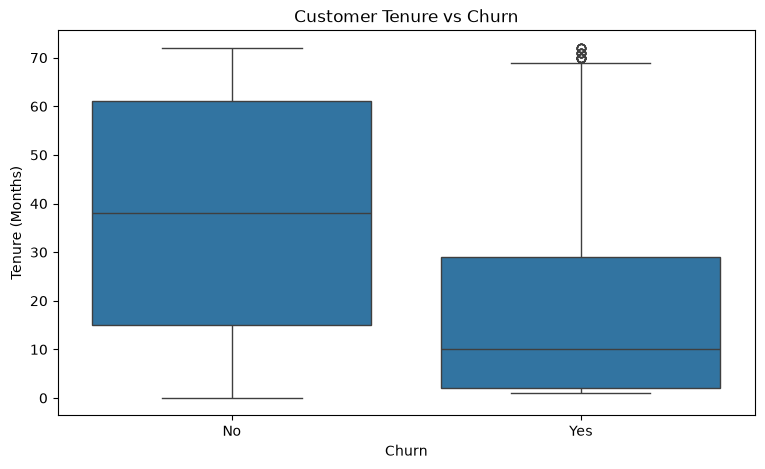

In [5]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

In [6]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


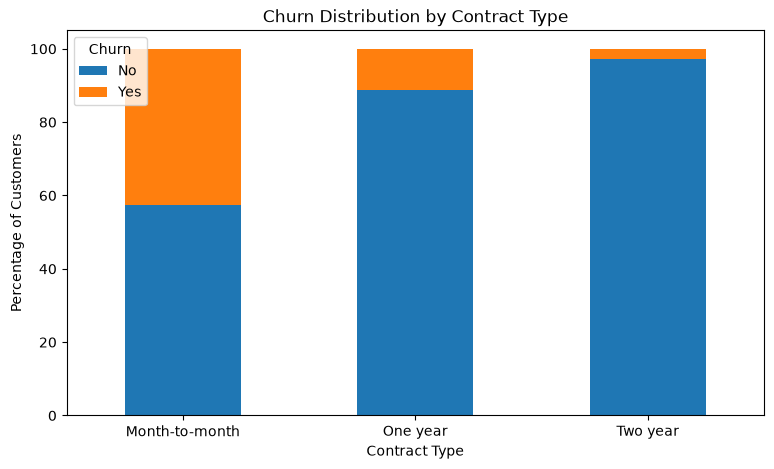

In [7]:
contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")

plt.legend(title="Churn")

plt.xticks(rotation=0)

plt.show()

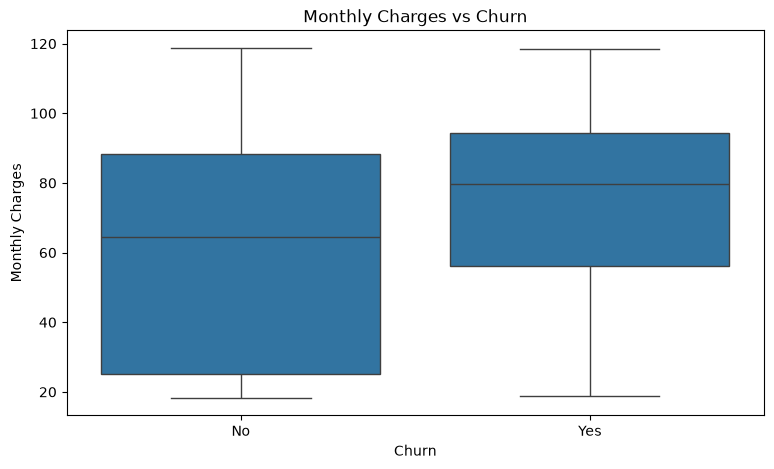

In [8]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [9]:
categorical_columns = df.select_dtypes(include="object").columns.tolist()

categorical_columns.remove("customerID")
categorical_columns.remove("Churn")

for column in categorical_columns:

    churn_rate = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    print(f"\n========== {column} ==========")
    print(churn_rate.round(2))

C:\Users\USER\AppData\Local\Temp\ipykernel_7248\4200789914.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns.tolist()



========== gender ==========
Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16

========== Partner ==========
Churn       No    Yes
Partner              
No       67.04  32.96
Yes      80.34  19.66

========== Dependents ==========
Churn          No    Yes
Dependents              
No          68.72  31.28
Yes         84.55  15.45

========== PhoneService ==========
Churn            No    Yes
PhoneService              
No            75.07  24.93
Yes           73.29  26.71

========== MultipleLines ==========
Churn                No    Yes
MultipleLines                 
No                74.96  25.04
No phone service  75.07  24.93
Yes               71.39  28.61

========== InternetService ==========
Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40

========== OnlineSecurity ==========
Churn                   No    Yes
OnlineSecurity                   
No

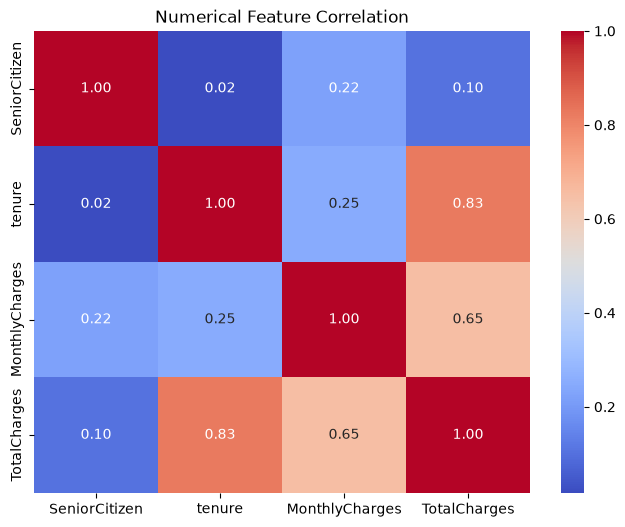

In [10]:
numerical_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

correlation = df[numerical_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")
plt.show()

In [11]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn.round(2))

Churn                         No    Yes
PaymentMethod                          
Bank transfer (automatic)  83.29  16.71
Credit card (automatic)    84.76  15.24
Electronic check           54.71  45.29
Mailed check               80.89  19.11


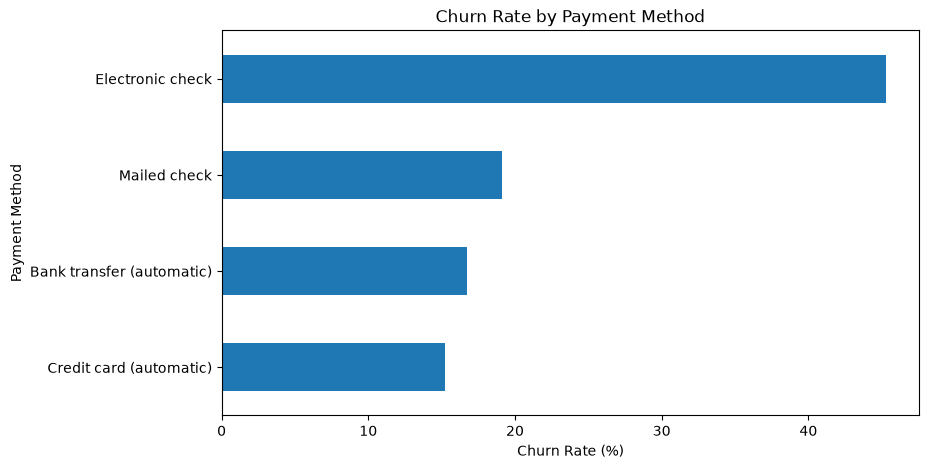

In [12]:
payment_churn["Yes"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Payment Method")
plt.show()

In [13]:
churn_summary = []

for column in categorical_columns:

    rates = df.groupby(column, observed=True)["Churn"].apply(
        lambda x: (x == "Yes").mean() * 100
    )

    for category, rate in rates.items():

        churn_summary.append({
            "Feature": column,
            "Category": category,
            "Churn_Rate": round(rate, 2)
        })

churn_summary = pd.DataFrame(churn_summary)

churn_summary = churn_summary.sort_values(
    by="Churn_Rate",
    ascending=False
)

churn_summary.head(20)

,Feature,Category,Churn_Rate
39,PaymentMethod,Electronic check,45.29
32,Contract,Month-to-month,42.71
12,InternetService,Fiber optic,41.89
14,OnlineSecurity,No,41.77
23,TechSupport,No,41.64
17,OnlineBackup,No,39.93
20,DeviceProtection,No,39.13
29,StreamingMovies,No,33.68
36,PaperlessBilling,Yes,33.57
26,StreamingTV,No,33.52


In [14]:
# Separate the target from the input features

X = df.drop(columns=["Churn", "customerID"])

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [15]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\USER\AppData\Local\Temp\ipykernel_7248\1998881318.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [17]:
def create_features(df):
    df = df.copy()

    # Group customers according to tenure
    df["tenure_group"] = pd.cut(
        df["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=[
            "0-12 months",
            "13-24 months",
            "25-48 months",
            "49-72 months"
        ]
    )

    return df

In [18]:
X_train = create_features(X_train)
X_test = create_features(X_test)

print(X_train.head())

      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
3738    Male              0      No         No      35           No   
3151    Male              0     Yes        Yes      15          Yes   
4860    Male              0     Yes        Yes      13           No   
3867  Female              0     Yes         No      26          Yes   
3810    Male              0     Yes        Yes       1          Yes   

         MultipleLines InternetService OnlineSecurity OnlineBackup  \
3738  No phone service             DSL             No           No   
3151                No     Fiber optic            Yes           No   
4860  No phone service             DSL            Yes          Yes   
3867                No             DSL             No          Yes   
3810                No             DSL             No           No   

     DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
3738              Yes          No         Yes             Yes  Month-to

In [19]:
def create_features(df):
    df = df.copy()

    df["tenure_group"] = pd.cut(
        df["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=[
            "0-12 months",
            "13-24 months",
            "25-48 months",
            "49-72 months"
        ]
    )

    df["average_monthly_spend"] = (
        df["TotalCharges"] /
        df["tenure"].replace(0, np.nan)
    )

    df["average_monthly_spend"] = (
        df["average_monthly_spend"].fillna(
            df["MonthlyCharges"]
        )
    )

    return df

In [20]:
def create_features(df):
    df = df.copy()

    df["tenure_group"] = pd.cut(
        df["tenure"],
        bins=[-1, 12, 24, 48, 72],
        labels=[
            "0-12 months",
            "13-24 months",
            "25-48 months",
            "49-72 months"
        ]
    )

    df["average_monthly_spend"] = (
        df["TotalCharges"] /
        df["tenure"].replace(0, np.nan)
    )

    df["average_monthly_spend"] = (
        df["average_monthly_spend"].fillna(
            df["MonthlyCharges"]
        )
    )

    service_columns = [
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies"
    ]

    df["service_count"] = (
        df[service_columns] == "Yes"
    ).sum(axis=1)

    return df

In [21]:
X_train = create_features(X_train)
X_test = create_features(X_test)

print(
    X_train[
        [
            "tenure",
            "tenure_group",
            "TotalCharges",
            "average_monthly_spend",
            "service_count"
        ]
    ].head(10)
)

      tenure  tenure_group  TotalCharges  average_monthly_spend  service_count
3738      35  25-48 months       1701.65              48.618571              3
3151      15  13-24 months       1151.55              76.770000              1
4860      13  13-24 months        590.35              45.411538              3
3867      26  25-48 months       1905.70              73.296154              4
3810       1   0-12 months         44.55              44.550000              0
2666      66  49-72 months       5196.10              78.728788              5
2645       1   0-12 months         19.80              19.800000              0
189       40  25-48 months       2379.10              59.477500              1
5767      65  49-72 months       3808.20              58.587692              2
2257      60  49-72 months       4847.05              80.784167              4


In [22]:
print("Tenure groups:")
print(X_train["tenure_group"].value_counts())

print("\nService count:")
print(X_train["service_count"].value_counts().sort_index())

print("\nAverage monthly spend:")
print(X_train["average_monthly_spend"].describe())

Tenure groups:
tenure_group
49-72 months    1789
0-12 months     1737
25-48 months    1290
13-24 months     818
Name: count, dtype: int64

Service count:
service_count
0    1757
1     766
2     832
3     885
4     695
5     464
6     235
Name: count, dtype: int64

Average monthly spend:
count    5634.000000
mean       64.938144
std        30.224872
min        13.828571
25%        36.045516
50%        70.588666
75%        90.464446
max       121.400000
Name: average_monthly_spend, dtype: float64


In [23]:
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'average_monthly_spend', 'service_count']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']


C:\Users\USER\AppData\Local\Temp\ipykernel_7248\3318738767.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [25]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [26]:
y_pred = logistic_model.predict(X_test)

y_probability = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 churn probabilities:")
print(y_probability[:10].round(3))

First 10 predictions:
[0 1 0 0 0 1 0 0 0 0]

First 10 churn probabilities:
[0.042 0.737 0.053 0.335 0.024 0.543 0.381 0.108 0.005 0.316]


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

print("========== MODEL PERFORMANCE ==========")

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_probability), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_probability), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

========== MODEL PERFORMANCE ==========
Accuracy: 0.7991
Precision: 0.6532
Recall: 0.5187
F1 Score: 0.5782
ROC-AUC: 0.8422
PR-AUC: 0.6365

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



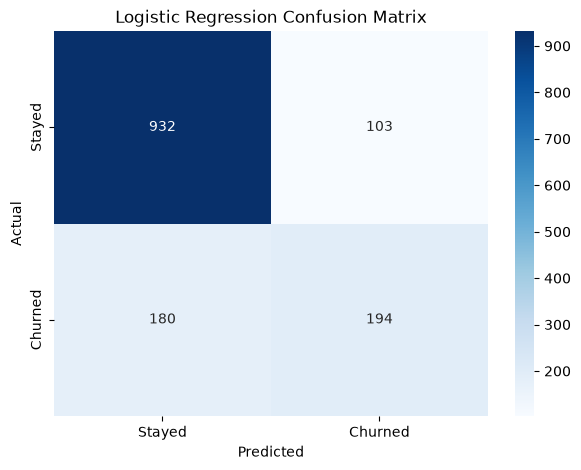

In [28]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [29]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

models = {
    "Logistic Regression": logistic_model,

    "Random Forest": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            ))
        ]
    ),

    "XGBoost": Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", XGBClassifier(
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            ))
        ]
    )
}

In [30]:
results = []

trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    if name == "Logistic Regression":
        trained_model = model
    else:
        trained_model = model.fit(X_train, y_train)

    trained_models[name] = trained_model

    predictions = trained_model.predict(X_test)

    probabilities = trained_model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "PR_AUC": average_precision_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR_AUC",
    ascending=False
)

results_df.round(4)


Training Logistic Regression...

Training Random Forest...

Training XGBoost...


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
2,XGBoost,0.8013,0.6610,0.5160,0.5796,0.8420,0.6503
0,Logistic Regression,0.7991,0.6532,0.5187,0.5782,0.8422,0.6365
1,Random Forest,0.7842,0.6190,0.4866,0.5449,0.8231,0.6148


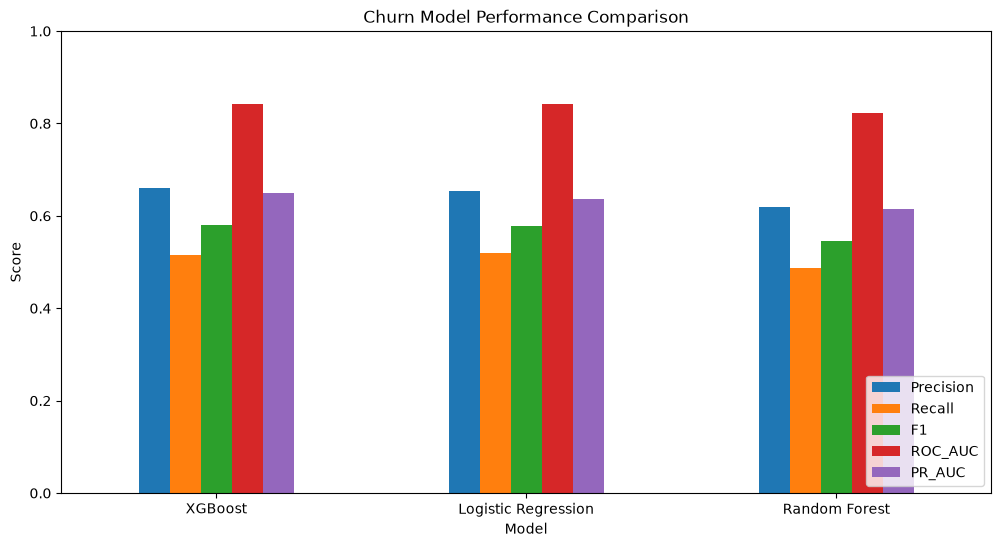

In [31]:
metrics = ["Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Churn Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

In [32]:
from sklearn.model_selection import train_test_split

X_fit, X_valid, y_fit, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Fitting data:", X_fit.shape)
print("Validation data:", X_valid.shape)

print("\nFitting churn distribution:")
print(y_fit.value_counts(normalize=True).round(3))

print("\nValidation churn distribution:")
print(y_valid.value_counts(normalize=True).round(3))

Fitting data: (4507, 22)
Validation data: (1127, 22)

Fitting churn distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Validation churn distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


def create_preprocessor():

    numerical_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]
    )

    categorical_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]
    )

    return ColumnTransformer(
        transformers=[
            (
                "num",
                numerical_pipeline,
                numerical_features
            ),
            (
                "cat",
                categorical_pipeline,
                categorical_features
            )
        ]
    )

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": Pipeline(
        steps=[
            ("preprocessor", create_preprocessor()),
            ("classifier", LogisticRegression(max_iter=1000))
        ]
    ),

    "Random Forest": Pipeline(
        steps=[
            ("preprocessor", create_preprocessor()),
            ("classifier", RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            ))
        ]
    ),

    "XGBoost": Pipeline(
        steps=[
            ("preprocessor", create_preprocessor()),
            ("classifier", XGBClassifier(
                n_estimators=300,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            ))
        ]
    )
}

trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_fit, y_fit)

    trained_models[name] = model

    print(f"{name} trained successfully.")


Training Logistic Regression...
Logistic Regression trained successfully.

Training Random Forest...
Random Forest trained successfully.

Training XGBoost...
XGBoost trained successfully.


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

validation_results = []

validation_probabilities = {}

for name, model in trained_models.items():

    probabilities = model.predict_proba(X_valid)[:, 1]

    predictions = (probabilities >= 0.5).astype(int)

    validation_probabilities[name] = probabilities

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Precision": precision_score(y_valid, predictions),
        "Recall": recall_score(y_valid, predictions),
        "F1": f1_score(y_valid, predictions),
        "ROC_AUC": roc_auc_score(y_valid, probabilities),
        "PR_AUC": average_precision_score(y_valid, probabilities)
    })

validation_results_df = pd.DataFrame(validation_results)

validation_results_df = validation_results_df.sort_values(
    by="PR_AUC",
    ascending=False
)

validation_results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.8181,0.7061,0.5385,0.6110,0.8480,0.6710
2,XGBoost,0.8012,0.6728,0.4883,0.5659,0.8491,0.6670
1,Random Forest,0.7941,0.6530,0.4783,0.5521,0.8283,0.6273


In [36]:
thresholds = [
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70,
    0.75,
    0.80
]

threshold_results = []

for name, probabilities in validation_probabilities.items():

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_valid,
                predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_valid,
                predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_valid,
                predictions,
                zero_division=0
            )
        })

threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df.round(4)

,Model,Threshold,Precision,Recall,F1
0,Logistic Regression,0.20,0.4667,0.8428,0.6007
1,Logistic Regression,0.25,0.5032,0.7893,0.6146
2,Logistic Regression,0.30,0.5441,0.7425,0.6280
3,Logistic Regression,0.35,0.5780,0.7191,0.6408
4,Logistic Regression,0.40,0.6262,0.6722,0.6484
5,Logistic Regression,0.45,0.6691,0.6020,0.6338
6,Logistic Regression,0.50,0.7061,0.5385,0.6110
7,Logistic Regression,0.55,0.7409,0.4783,0.5813
8,Logistic Regression,0.60,0.7613,0.3946,0.5198
9,Logistic Regression,0.65,0.7479,0.2977,0.4258


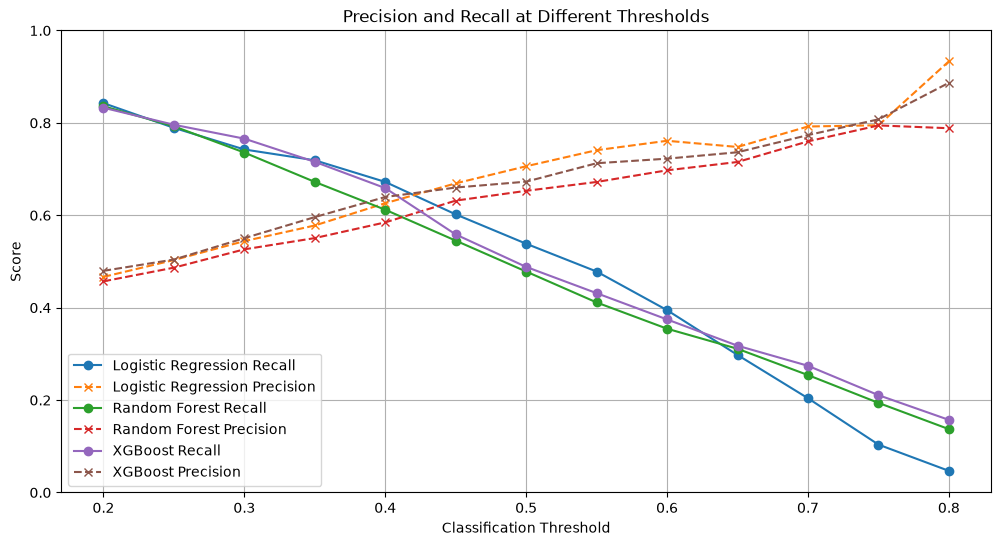

In [37]:
plt.figure(figsize=(12, 6))

for name in trained_models:

    model_results = threshold_results_df[
        threshold_results_df["Model"] == name
    ]

    plt.plot(
        model_results["Threshold"],
        model_results["Recall"],
        marker="o",
        label=f"{name} Recall"
    )

    plt.plot(
        model_results["Threshold"],
        model_results["Precision"],
        marker="x",
        linestyle="--",
        label=f"{name} Precision"
    )

plt.title("Precision and Recall at Different Thresholds")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

Confusion Matrix:
[[683 145]
 [ 85 214]]

Business interpretation:
True Negatives: 683
False Positives: 145
False Negatives: 85
True Positives: 214

Customers flagged for retention: 359
Actual churners identified: 214
Actual churners missed: 85


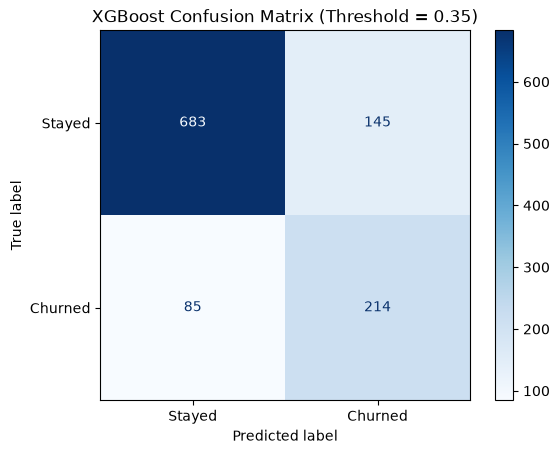

In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

selected_model = trained_models["XGBoost"]
selected_threshold = 0.35

valid_probabilities = selected_model.predict_proba(X_valid)[:, 1]

valid_predictions = (
    valid_probabilities >= selected_threshold
).astype(int)

cm = confusion_matrix(y_valid, valid_predictions)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nBusiness interpretation:")
print(f"True Negatives: {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives: {tp}")

print(f"\nCustomers flagged for retention: {tp + fp}")
print(f"Actual churners identified: {tp}")
print(f"Actual churners missed: {fn}")

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

display.plot(cmap="Blues")
plt.title("XGBoost Confusion Matrix (Threshold = 0.35)")
plt.show()

In [39]:
total_customers = len(y_valid)

flagged_customers = tp + fp

actual_churners = tp + fn

print(
    f"Total validation customers: {total_customers}"
)

print(
    f"Customers flagged: {flagged_customers}"
)

print(
    f"Percentage flagged: "
    f"{(flagged_customers / total_customers) * 100:.2f}%"
)

print(
    f"Actual churners identified: "
    f"{(tp / actual_churners) * 100:.2f}%"
)

print(
    f"Unnecessary interventions: {fp}"
)

Total validation customers: 1127
Customers flagged: 359
Percentage flagged: 31.85%
Actual churners identified: 71.57%
Unnecessary interventions: 145


In [40]:
# Rebuild the final XGBoost pipeline

final_model = Pipeline(
    steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train using all original training data
final_model.fit(X_train, y_train)

print("Final XGBoost model trained.")

Final XGBoost model trained.


Final Test Performance
Accuracy: 0.7779
Precision: 0.5659
Recall: 0.7005
F1: 0.6260
ROC-AUC: 0.8420
PR-AUC: 0.6503

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.88      0.81      0.84      1035
     Churned       0.57      0.70      0.63       374

    accuracy                           0.78      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.78      0.78      1409



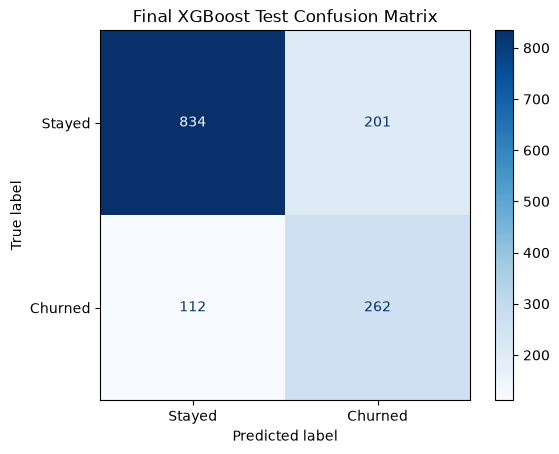

In [41]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

FINAL_THRESHOLD = 0.35

test_probabilities = final_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= FINAL_THRESHOLD
).astype(int)

print("Final Test Performance")

print(
    f"Accuracy: {accuracy_score(y_test, test_predictions):.4f}"
)

print(
    f"Precision: {precision_score(y_test, test_predictions):.4f}"
)

print(
    f"Recall: {recall_score(y_test, test_predictions):.4f}"
)

print(
    f"F1: {f1_score(y_test, test_predictions):.4f}"
)

print(
    f"ROC-AUC: {roc_auc_score(y_test, test_probabilities):.4f}"
)

print(
    f"PR-AUC: {average_precision_score(y_test, test_probabilities):.4f}"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Stayed", "Churned"]
    )
)

cm = confusion_matrix(y_test, test_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

display.plot(cmap="Blues")
plt.title("Final XGBoost Test Confusion Matrix")
plt.show()

In [42]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


In [43]:
# Extract the fitted preprocessing component
fitted_preprocessor = final_model.named_steps["preprocessor"]

# Extract the fitted XGBoost classifier
xgb_classifier = final_model.named_steps["classifier"]

# Transform test data using the already-fitted preprocessor
X_test_transformed = fitted_preprocessor.transform(X_test)

# Get the names of the transformed features
feature_names = fitted_preprocessor.get_feature_names_out()

# Convert transformed data into a DataFrame
X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

print("Original features:", X_test.shape[1])
print("Transformed features:", X_test_transformed_df.shape[1])

X_test_transformed_df.head()

Original features: 22
Transformed features: 51


,num__SeniorCitizen,num__tenure,num__MonthlyCharges,num__TotalCharges,num__average_monthly_spend,num__service_count,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,...,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check,cat__tenure_group_0-12 months,cat__tenure_group_13-24 months,cat__tenure_group_25-48 months,cat__tenure_group_49-72 months
437,-0.441773,1.608483,1.629976,2.706828,1.742949,2.125633,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2280,2.263606,-0.996684,1.168725,-0.610260,1.609103,0.507935,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2235,-0.441773,0.346606,0.445324,0.400116,0.442847,1.047168,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4460,-0.441773,-0.589626,0.440347,-0.364451,0.551220,-0.031297,0.0,1.0,0.0,1.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3761,-0.441773,1.608483,0.588013,1.588421,0.571602,1.586400,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [44]:
# Select a sample of test customers
X_shap = X_test_transformed_df.sample(
    n=min(500, len(X_test_transformed_df)),
    random_state=42
)

# Create the SHAP explainer
explainer = shap.TreeExplainer(xgb_classifier)

# Calculate SHAP values
shap_values = explainer(X_shap)

print("SHAP calculation complete.")

SHAP calculation complete.


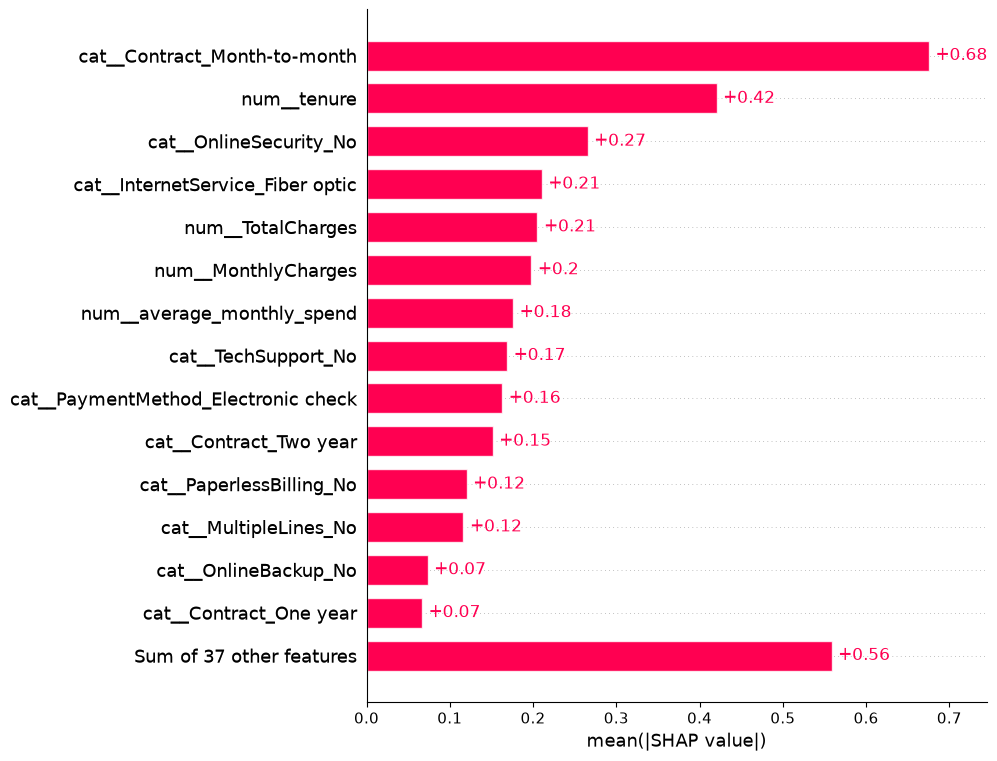

In [45]:
shap.plots.bar(shap_values, max_display=15)

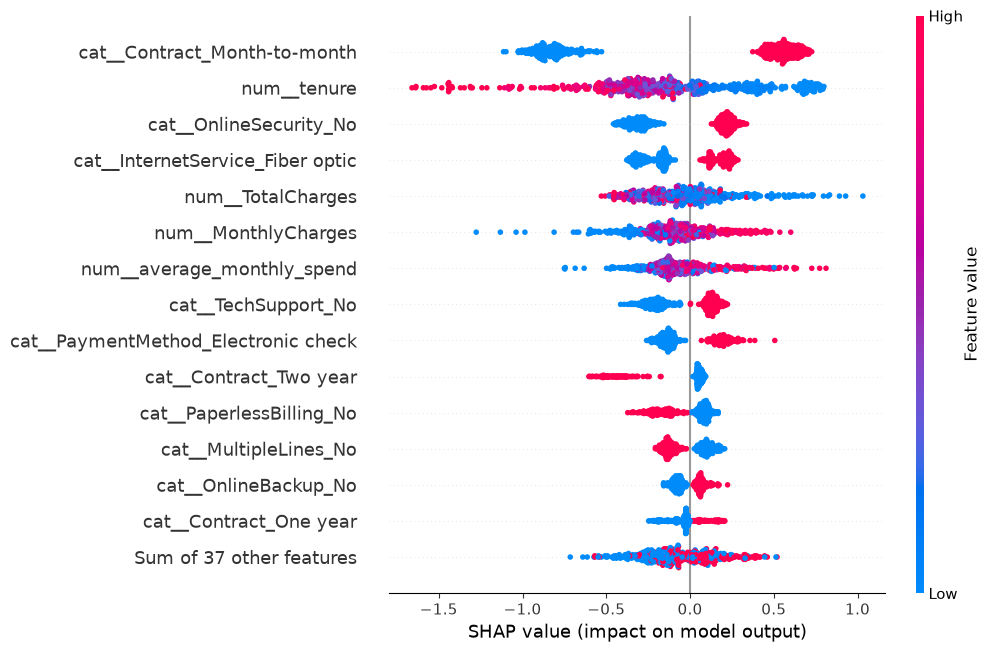

In [46]:
shap.plots.beeswarm(
    shap_values,
    max_display=15
)

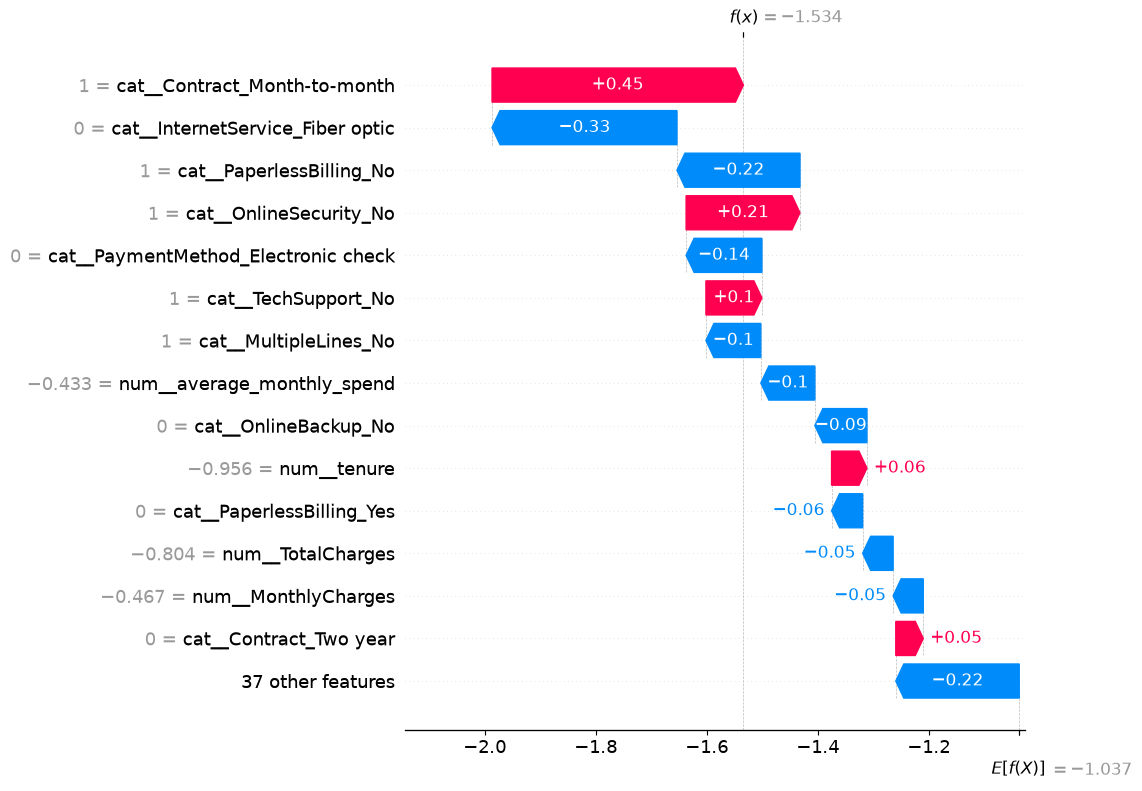

In [47]:
# Select one customer from the SHAP sample
customer_index = 0

customer_shap_values = shap_values[customer_index]

# Show the customer's SHAP explanation
shap.plots.waterfall(
    customer_shap_values,
    max_display=15
)

In [48]:
shap_importance = pd.DataFrame({
    "Feature": shap_values.feature_names,
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

shap_importance.head(15).round(4)

,Feature,Mean_Absolute_SHAP
38,cat__Contract_Month-to-month,0.6754
1,num__tenure,0.4203
20,cat__OnlineSecurity_No,0.2654
18,cat__InternetService_Fiber optic,0.2104
3,num__TotalCharges,0.2052
2,num__MonthlyCharges,0.1979
4,num__average_monthly_spend,0.1759
29,cat__TechSupport_No,0.1688
45,cat__PaymentMethod_Electronic check,0.1629
40,cat__Contract_Two year,0.1514


In [49]:
shap_direction = pd.DataFrame({
    "Feature": shap_values.feature_names,
    "Mean_SHAP": shap_values.values.mean(axis=0),
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=0)
})

shap_direction = shap_direction.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

shap_direction.head(15).round(4)

,Feature,Mean_SHAP,Mean_Absolute_SHAP
38,cat__Contract_Month-to-month,-0.0524,0.6754
1,num__tenure,-0.1404,0.4203
20,cat__OnlineSecurity_No,-0.0337,0.2654
18,cat__InternetService_Fiber optic,-0.0486,0.2104
3,num__TotalCharges,-0.0140,0.2052
2,num__MonthlyCharges,-0.0894,0.1979
4,num__average_monthly_spend,-0.0435,0.1759
29,cat__TechSupport_No,-0.0307,0.1688
45,cat__PaymentMethod_Electronic check,-0.0165,0.1629
40,cat__Contract_Two year,-0.0648,0.1514


In [53]:
features_to_investigate = [
    "cat__Contract_Month-to-month",
    "cat__Contract_Two year",
    "cat__OnlineSecurity_No",
    "cat__InternetService_Fiber optic",
    "cat__TechSupport_No",
    "cat__PaymentMethod_Electronic check"
]

direction_results = []

for feature in features_to_investigate:

    for value in [0, 1]:

        mask = X_shap[feature] == value

        direction_results.append({
            "Feature": feature,
            "Feature_Value": value,
            "Customer_Count": mask.sum(),
            "Mean_SHAP": shap_values[:, feature].values[mask].mean()
        })

direction_df = pd.DataFrame(direction_results)

direction_df.round(4)

,Feature,Feature_Value,Customer_Count,Mean_SHAP
0,cat__Contract_Month-to-month,0,220,-0.8270
1,cat__Contract_Month-to-month,1,280,0.5562
2,cat__Contract_Two year,0,379,0.0571
3,cat__Contract_Two year,1,121,-0.4465
4,cat__OnlineSecurity_No,0,238,-0.3142
5,cat__OnlineSecurity_No,1,262,0.2211
6,cat__InternetService_Fiber optic,0,282,-0.2296
7,cat__InternetService_Fiber optic,1,218,0.1855
8,cat__TechSupport_No,0,238,-0.2095
9,cat__TechSupport_No,1,262,0.1318


In [54]:
customer_index = 0

customer_explanation = pd.DataFrame({
    "Feature": shap_values.feature_names,
    "Feature_Value": X_shap.iloc[customer_index].values,
    "SHAP_Value": shap_values.values[customer_index]
})

customer_explanation["Absolute_SHAP"] = (
    customer_explanation["SHAP_Value"].abs()
)

customer_explanation = customer_explanation.sort_values(
    by="Absolute_SHAP",
    ascending=False
)

customer_probability = final_model.predict_proba(
    X_test.loc[[X_shap.index[customer_index]]]
)[0, 1]

print(f"Predicted churn probability: {customer_probability:.4f}")

display(customer_explanation.head(10).round(4))

Predicted churn probability: 0.1774


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [52]:
from src.models.save_model import save_model

save_model(
    model=final_model,
    threshold=0.35
)

ModuleNotFoundError: No module named 'src'

In [55]:
import joblib
import json

loaded_model = joblib.load(
    "artifacts/models/churn_model.joblib"
)

with open(
    "artifacts/models/model_metadata.json",
    "r"
) as file:
    metadata = json.load(file)

print("Model:", metadata["model_name"])
print("Threshold:", metadata["threshold"])

sample_customer = X_test.iloc[[0]]

probability = loaded_model.predict_proba(
    sample_customer
)[0, 1]

prediction = int(
    probability >= metadata["threshold"]
)

print(f"Churn probability: {probability:.4f}")
print(f"Churn prediction: {prediction}")

Model: XGBoost
Threshold: 0.35
Churn probability: 0.0095
Churn prediction: 0


In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("src exists:", (PROJECT_ROOT / "src").exists())

In [56]:
import sys
import importlib
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.models.save_model

importlib.reload(src.models.save_model)

src.models.save_model.save_model(
    model=final_model,
    threshold=0.35
)

Model saved to: C:\Users\USER\Documents\Projects\customer-retention-agent\artifacts\models\churn_model.joblib
Metadata saved to: C:\Users\USER\Documents\Projects\customer-retention-agent\artifacts\models\model_metadata.json


In [57]:
from src.models.save_model import save_model

save_model(
    model=final_model,
    threshold=0.35
)

Model saved to: C:\Users\USER\Documents\Projects\customer-retention-agent\artifacts\models\churn_model.joblib
Metadata saved to: C:\Users\USER\Documents\Projects\customer-retention-agent\artifacts\models\model_metadata.json


In [58]:
print(final_model)
print("Model features:", len(final_model.feature_names_in_))

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'average_monthly_spend',
                                                   'service_count']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   Sim